# Анализ поведения посетителей интернет-магазина

Цель: исследовать путь от просмотра товара до добавления в корзину и покупки.
Данные: Retailrocket Ecommerce Dataset, файл events.csv.

In [25]:
import kagglehub
import pandas as pd


events_path = kagglehub.dataset_download(
    "retailrocket/ecommerce-dataset",
    path="events.csv"
)


print("Path to events.csv file:", events_path)
events = pd.read_csv(events_path)
events.head()

Path to events.csv file: /Users/mikhailzayats/.cache/kagglehub/datasets/retailrocket/ecommerce-dataset/versions/2/events.csv


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [26]:
events.dtypes

timestamp          int64
visitorid          int64
event                str
itemid             int64
transactionid    float64
dtype: object

In [27]:
events["event"].unique()

<StringArray>
['view', 'addtocart', 'transaction']
Length: 3, dtype: str

In [28]:
events.isna().sum()

timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

In [29]:
events.groupby("event")["transactionid"].apply(lambda column: column.isna().sum())

event
addtocart        69332
transaction          0
view           2664312
Name: transactionid, dtype: int64

In [30]:
events["event_time"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

events[["timestamp", "event_time"]].head()

,timestamp,event_time
0,1433221332117,2015-06-02 05:02:12.117000+00:00
1,1433224214164,2015-06-02 05:50:14.164000+00:00
2,1433221999827,2015-06-02 05:13:19.827000+00:00
3,1433221955914,2015-06-02 05:12:35.914000+00:00
4,1433221337106,2015-06-02 05:02:17.106000+00:00


In [31]:
events["event_time"].min(), events["event_time"].max()

(Timestamp('2015-05-03 03:00:04.384000+0000', tz='UTC'),
 Timestamp('2015-09-18 02:59:47.788000+0000', tz='UTC'))

Хочу узнать, есть ли полные дубликаты данных. Для этого по всей таблице сделаю поиск на полные дубликаты. Если найду их, проверю, прежде чем удалять.

In [32]:
duplicates = events.duplicated().value_counts()
print(duplicates)

False    2755641
True         460
Name: count, dtype: int64


In [33]:
events.loc[events.duplicated(), "event"].value_counts()

event
addtocart    366
view          94
Name: count, dtype: int64

Дубликаты найдены для событий `addtocart` (366) и `view` (94). Это полные дупликаты, в которых совпадает время события до милисекунд, поэтому каждый дубликат можно удалить. На целостность таблицы это никак не повлияет, а вот при подсчетах лишние строки могут исказить метрики.

In [34]:
events_clean = events.drop_duplicates()

print("Было строк до очистки от дубликатов: ", len(events))
print("Стало строк после очистки от дубликатов: ", len(events_clean))
print("Удалено: ", len(events) - len(events_clean))

Было строк до очистки от дубликатов:  2756101
Стало строк после очистки от дубликатов:  2755641
Удалено:  460


Хочу узнать, может ли один visitorid совершить любое из событий несколько раз. Для этого построю таблицу с кол-вом каждого из событий для каждого visitorid.

In [35]:
event_counts = (
    events_clean
    .groupby(["visitorid", "event"])
    .size()
    .unstack(fill_value=0)
)

event_counts.head()

event,addtocart,transaction,view
visitorid,,,
0,0,0,3
1,0,0,1
2,0,0,8
3,0,0,1
4,0,0,1


Результат показал, что visitorid может выполнять несколько раз одно и тоже действие, а значит **кол-во visitorid != кол-во событий**

Сколько уникальных посетителей просматривали товары, добавляли их в корзину и совершали покупки?

In [36]:
visitors_by_event = (
    events_clean
    .groupby("event")["visitorid"]
    .nunique()
)

visitors_by_event.sort_values(ascending=False)

event
view           1404179
addtocart        37722
transaction      11719
Name: visitorid, dtype: int64

In [37]:
events_clean["event"].value_counts()

event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64

Теперь будем искать для пар `visitorid` + `itemid` время их первого `view`

In [38]:
first_item_view = (
    events_clean[events_clean["event"] == 'view']
    .groupby(["visitorid", "itemid"])["event_time"]
    .min()
)

print(first_item_view.head(10))
print("Число таких пар: ", len(first_item_view))

visitorid  itemid
0          67045    2015-09-11 20:55:17.175000+00:00
           285930   2015-09-11 20:49:49.439000+00:00
           357564   2015-09-11 20:52:39.591000+00:00
1          72028    2015-08-13 17:46:06.444000+00:00
2          216305   2015-08-07 18:01:08.920000+00:00
           259884   2015-08-07 17:56:52.664000+00:00
           325215   2015-08-07 17:51:44.567000+00:00
           342816   2015-08-07 18:08:25.669000+00:00
3          385090   2015-08-01 07:10:35.296000+00:00
4          177677   2015-09-15 21:24:27.167000+00:00
Name: event_time, dtype: datetime64[ms, UTC]
Число таких пар:  2132127


Ответим на вопрос: Для скольких пар `visitorid–itemid` было добавление в корзину после первого просмотра этого товара?

In [39]:
first_views = first_item_view.reset_index(name="first_view_time")

carts = events_clean.loc[
    events_clean["event"] == "addtocart",
    ["visitorid", "itemid", "event_time"]
]

carts_with_view = carts.merge(
    first_views,
    on=["visitorid", "itemid"],
    how="inner",
    validate="many_to_one"
)

carts_with_view.head()

,visitorid,itemid,event_time,first_view_time
0,287857,5206,2015-06-02 05:33:56.124000+00:00,2015-06-02 05:33:13.721000+00:00
1,158090,10572,2015-06-02 04:57:58.505000+00:00,2015-06-02 04:54:51.020000+00:00
2,1193904,255275,2015-06-02 05:39:03.021000+00:00,2015-06-02 05:38:26.341000+00:00
3,599528,356475,2015-06-02 05:12:21.632000+00:00,2015-06-02 05:11:36.102000+00:00
4,105775,312728,2015-06-02 04:54:40.956000+00:00,2015-06-02 04:53:59.886000+00:00


Далее оставим только те пары, где дата и время первого просмотра раньше добавления в корзину

In [40]:
carts_after_view = carts_with_view.loc[
    carts_with_view["event_time"] > carts_with_view["first_view_time"]
]

first_item_cart = (
    carts_after_view
    .groupby(["visitorid", "itemid"])["event_time"]
    .min()
)

print("Кол-во строк, где разница во времени просмотра и добавления в корзину не отслеживается:", len(carts_with_view))
print("Кол-во строк, где первое добавление в корзину произошло после первого просмотра:", len(first_item_cart))

Кол-во строк, где разница во времени просмотра и добавления в корзину не отслеживается: 55045
Кол-во строк, где первое добавление в корзину произошло после первого просмотра: 45804


Полученное кол-во уникальных добавлений товара в корзину после просмотра товара составило: **45804**

Теперь проделаем тоже самое, но уже для покупок

In [41]:
purchases = events_clean.loc[
    events_clean["event"] == "transaction",
    ["visitorid", "itemid", "event_time"]
]

purchases_with_carts = purchases.merge(
    first_item_cart,
    on=["visitorid", "itemid"],
    how="inner",
    validate="many_to_one",
    suffixes=("_purchase", "_cart")
)

purchases_after_cart = purchases_with_carts.loc[
    purchases_with_carts["event_time_purchase"] > purchases_with_carts["event_time_cart"]
]

first_purchase_after_cart = (
    purchases_after_cart
    .groupby(["visitorid", "itemid"])["event_time_purchase"]
    .min()
)

Теперь посчитаем размеры трёх этапов и доли перехода:

In [42]:
views_count = len(first_item_view)
carts_count = len(first_item_cart)
purchases_count = len(first_purchase_after_cart)

print("Просмотрели товар:", views_count)
print("Добавили после просмотра:", carts_count)
print("Купили после добавления:", purchases_count)

print(f"Просмотр → корзина: {carts_count / views_count:.1%}")
print(f"Корзина → покупка: {purchases_count / carts_count:.1%}")
print(f"Просмотр → покупка через корзину: {purchases_count / views_count:.1%}")

Просмотрели товар: 2132127
Добавили после просмотра: 45804
Купили после добавления: 16695
Просмотр → корзина: 2.1%
Корзина → покупка: 36.4%
Просмотр → покупка через корзину: 0.8%


Теперь проанализируем время между первым просмотром товара и первым добавлением в корзину

In [43]:
view_to_cart_days = (
    first_item_cart - first_item_view.loc[first_item_cart.index]
).dt.total_seconds() / 86400

cart_to_purchase_days = (
    first_purchase_after_cart - first_item_cart.loc[first_purchase_after_cart.index]
).dt.total_seconds() / 86400

summary = pd.DataFrame({
    "Переход": ["Просмотр → корзина", "Корзина → покупка"],
    "Медиана, мин": [
        view_to_cart_days.median() * 1440,
        cart_to_purchase_days.median() * 1440,
    ],
    "90% перешли за, ч": [
        view_to_cart_days.quantile(0.9) * 24,
        cart_to_purchase_days.quantile(0.9) * 24,
    ],
    "99% перешли за, дни": [
        view_to_cart_days.quantile(0.99),
        cart_to_purchase_days.quantile(0.99),
    ],
}).round(1)

display(summary)

,Переход,"Медиана, мин","90% перешли за, ч","99% перешли за, дни"
0,Просмотр → корзина,1.5,1.9,17.3
1,Корзина → покупка,4.3,0.8,5.6


Для итоговой воронке выберем такие пары, при которых корзина и покупка произошли не больше чем через 7 дней с момента просмотра. Для этого удалим из данных о просмотрах те пары, которые произошли за последние 7 дней выгрузки.

In [44]:
window = pd.Timedelta(days=7)
cutoff = events_clean["event_time"].max() - window

views_7d = first_item_view.loc[first_item_view <= cutoff]

carts_7d = first_item_cart.loc[
    first_item_cart.index.isin(views_7d.index)
]
carts_7d = carts_7d.loc[
    carts_7d <= views_7d.loc[carts_7d.index] + window
]

purchases_7d = first_purchase_after_cart.loc[
    first_purchase_after_cart.index.isin(carts_7d.index)
]
purchases_7d = purchases_7d.loc[
    purchases_7d <= views_7d.loc[purchases_7d.index] + window
]

print("Просмотр:", len(views_7d))
print("Корзина:", len(carts_7d))
print("Покупка:", len(purchases_7d))
print(f"Просмотр → корзина: {len(carts_7d) / len(views_7d):.1%}")
print(f"Корзина → покупка: {len(purchases_7d) / len(carts_7d):.1%}")

Просмотр: 2042310
Корзина: 43147
Покупка: 15520
Просмотр → корзина: 2.1%
Корзина → покупка: 36.0%


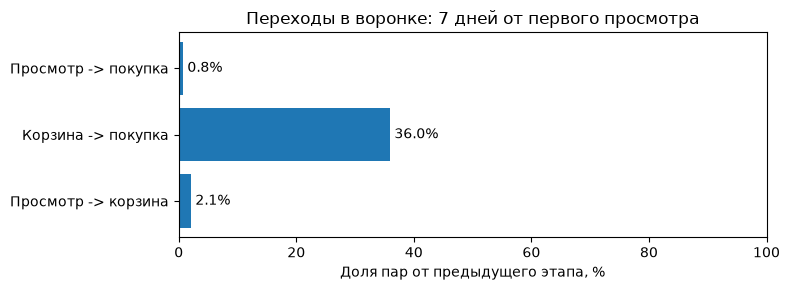

In [45]:
import matplotlib.pyplot as plt

transitions = ["Просмотр -> корзина", "Корзина -> покупка", "Просмотр -> покупка"]
rates = [
    len(carts_7d) / len(views_7d) * 100,
    len(purchases_7d) / len(carts_7d) * 100,
    len(purchases_7d) / len(views_7d) * 100,
]

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(transitions, rates)
ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.set_xlim(0, 100)
ax.set_xlabel("Доля пар от предыдущего этапа, %")
ax.set_title("Переходы в воронке: 7 дней от первого просмотра")

plt.tight_layout()
plt.show()

## Вывод

Единица анализа - уникальная пара «посетитель–товар». Корзина и покупка учитываются, если произошли в нужном порядке в течение 7 дней от первого просмотра. В корзину перешли 2,1% пар, а из корзины к покупке — 36,0%. Весь путь прошли 0,76% просмотренных пар. Покупки без наблюдаемого добавления в корзину в эту воронку не входят.